# Step 7 - Pretrain, then adapt with scarce labels

**Question:** does self-supervised pretraining on spikes make the model more *label-efficient*?

**Setting.** In co-smoothing the scarce thing is the held-out neurons' activity (think: newly recorded neurons).
Held-in spikes are plentiful and need no labels, so:

1. **Pretrain** on held-in spikes only (masked reconstruction, no held-out label used; early stopping on held-in dev loss).
2. **Adapt** with a fraction of the held-out labels (10%, 25%, 50%, 100% of the 1,463 fit trials), in three ways:
   *scratch* (random init, same recipe), *fine-tune* (pretrained init, all weights), *probe* (pretrained encoder frozen, head only).
3. **GLM** (50 ms smoothing + Poisson GLM, NLB-reference style) trained on the same labelled trials, so the
   comparison includes the best non-neural baseline and not just the weakest model.

Every arm gets the same step budget (8,000), the same nested labelled subsets, and a learning rate (and for the GLM, alpha) chosen on a dev
subset of the same fraction, never on the validation split. 5 seeds. Scores are NLB-official co-bps on the public validation split.

This notebook only reads saved results, so it runs in seconds.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

R = Path("../results/pretrain_v2")
rows = json.loads((R / "all_runs.json").read_text()) + json.loads((R / "glm_runs.json").read_text())
FR = [0.1, 0.25, 0.5, 1.0]
MODES = ["glm", "scratch", "finetune", "probe"]
NAME = {"glm": "GLM (same labels)", "scratch": "Transformer, scratch",
        "finetune": "Pretrained + fine-tune", "probe": "Pretrained, frozen + probe"}
COL = {"glm": "#7F7F7F", "scratch": "#4C78A8", "finetune": "#D9822B", "probe": "#8E6BBF"}

def per_seed(m, f):
    return {r["seed"]: r["val_co_bps"] for r in rows if r["mode"] == m and r["frac"] == f}

n_lab = {f: [r["n_labelled_trials"] for r in rows if r["mode"] == "scratch" and r["frac"] == f][0] for f in FR}
tab = pd.DataFrame({NAME[m]: [f"{np.mean(list(per_seed(m, f).values())):.3f} ± "
                              f"{np.std(list(per_seed(m, f).values()), ddof=1):.3f}" for f in FR]
                    for m in MODES}, index=[f"{int(f*100)}% ({n_lab[f]} trials)" for f in FR])
tab

,GLM (same labels),"Transformer, scratch",Pretrained + fine-tune,"Pretrained, frozen + probe"
10% (146 trials),0.139 ± 0.002,0.023 ± 0.006,0.176 ± 0.015,0.182 ± 0.061
25% (366 trials),0.171 ± 0.001,0.204 ± 0.026,0.261 ± 0.007,0.252 ± 0.042
50% (732 trials),0.186 ± 0.003,0.283 ± 0.013,0.304 ± 0.014,0.274 ± 0.036
100% (1463 trials),0.209 ± 0.000,0.332 ± 0.002,0.337 ± 0.017,0.282 ± 0.035


## Figure 6 - label efficiency

Left: validation co-bps against the number of labelled trials (mean of 5 seeds; faint dots are seeds).
Right: paired gain of fine-tuning over the two baselines, computed per seed, then shown as mean and individual seeds.

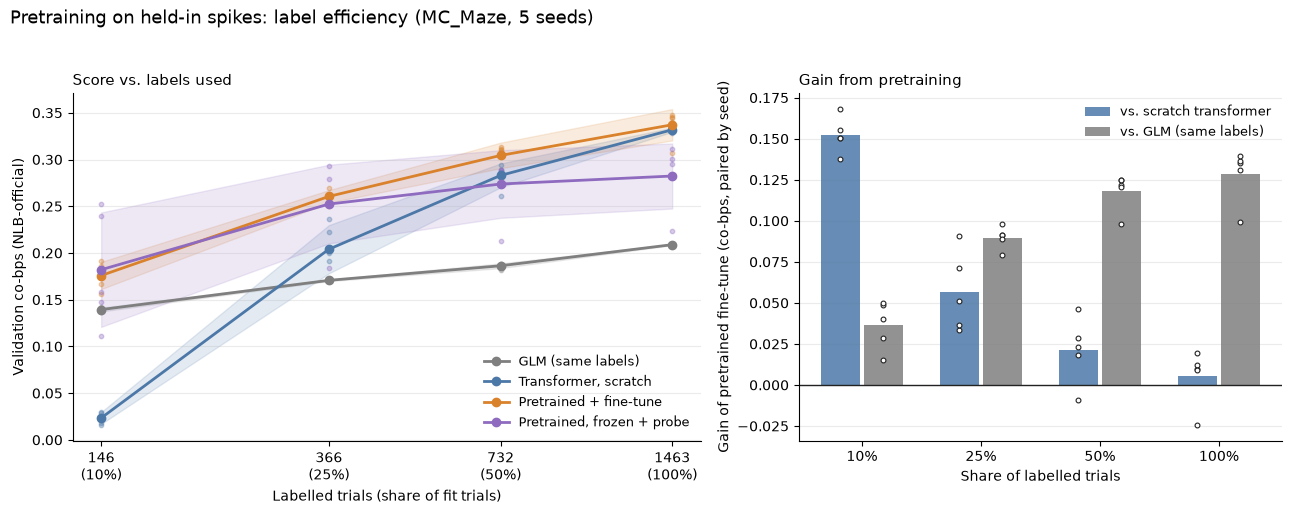

In [2]:
fig, (a0, a1) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
xs = np.array([n_lab[f] for f in FR])
for m in MODES:
    mean = np.array([np.mean(list(per_seed(m, f).values())) for f in FR])
    sd = np.array([np.std(list(per_seed(m, f).values()), ddof=1) for f in FR])
    a0.plot(xs, mean, "-o", color=COL[m], lw=2, ms=6, label=NAME[m], zorder=3)
    a0.fill_between(xs, mean - sd, mean + sd, color=COL[m], alpha=0.15, zorder=1)
    for f, x in zip(FR, xs):
        v = list(per_seed(m, f).values())
        a0.scatter(np.full(len(v), x), v, s=10, color=COL[m], alpha=0.35, zorder=2)
a0.set_xscale("log")
a0.set_xticks(xs)
a0.set_xticklabels([f"{n}\n({int(f*100)}%)" for n, f in zip(xs, FR)])
a0.minorticks_off()
a0.set_xlabel("Labelled trials (share of fit trials)")
a0.set_ylabel("Validation co-bps (NLB-official)")
a0.set_title("Score vs. labels used", loc="left", fontsize=11)
a0.legend(frameon=False, loc="lower right", fontsize=9)

width = 0.36
for j, (base, lab, c) in enumerate([("scratch", "vs. scratch transformer", "#4C78A8"),
                                    ("glm", "vs. GLM (same labels)", "#7F7F7F")]):
    for i, f in enumerate(FR):
        ft, bs = per_seed("finetune", f), per_seed(base, f)
        d = np.array([ft[s] - bs[s] for s in sorted(ft)])
        x = i + (j - 0.5) * width
        a1.bar(x, d.mean(), width * 0.92, color=c, alpha=0.85, zorder=2,
               label=lab if i == 0 else None)
        a1.scatter(np.full(len(d), x), d, s=12, color="white", edgecolor="#222222", lw=0.8, zorder=4)
a1.axhline(0, color="#222222", lw=1)
a1.set_xticks(range(len(FR)))
a1.set_xticklabels([f"{int(f*100)}%" for f in FR])
a1.set_xlabel("Share of labelled trials")
a1.set_ylabel("Gain of pretrained fine-tune (co-bps, paired by seed)")
a1.set_title("Gain from pretraining", loc="left", fontsize=11)
a1.legend(frameon=False, fontsize=9, loc="upper right")
for a in (a0, a1):
    a.spines[["top", "right"]].set_visible(False)
    a.grid(axis="y", alpha=0.25, zorder=0)
fig.suptitle("Pretraining on held-in spikes: label efficiency (MC_Maze, 5 seeds)", x=0.01, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
Path("../figures").mkdir(exist_ok=True)
fig.savefig("../figures/fig6_label_efficiency.png", dpi=160, bbox_inches="tight", facecolor="white")
plt.show()

## Paired gains, per seed

Seeds pair up because the labelled subset, dev fold and pretrained encoder are shared between arms.

In [3]:
out = []
for f in FR:
    ft = per_seed("finetune", f)
    for base in ("scratch", "glm"):
        b = per_seed(base, f)
        d = np.array([ft[s] - b[s] for s in sorted(ft)])
        out.append({"labels": f"{int(f*100)}%", "fine-tune minus": base, "mean": d.mean().round(4),
                    "per seed": d.round(3).tolist(), "positive in": f"{int((d > 0).sum())}/5"})
pd.DataFrame(out)

,labels,fine-tune minus,mean,per seed,positive in
0,10%,scratch,0.1525,"[0.155, 0.15, 0.151, 0.168, 0.138]",5/5
1,10%,glm,0.0364,"[0.049, 0.028, 0.04, 0.05, 0.015]",5/5
2,25%,scratch,0.0565,"[0.091, 0.051, 0.071, 0.033, 0.036]",5/5
3,25%,glm,0.0898,"[0.091, 0.079, 0.092, 0.098, 0.089]",5/5
4,50%,scratch,0.0214,"[0.029, 0.023, -0.009, 0.018, 0.046]",4/5
5,50%,glm,0.1181,"[0.125, 0.122, 0.098, 0.125, 0.121]",5/5
6,100%,scratch,0.0054,"[0.01, 0.012, 0.02, -0.024, 0.009]",4/5
7,100%,glm,0.1283,"[0.135, 0.137, 0.14, 0.099, 0.131]",5/5


## What this shows

* **Against the GLM trained on the same labels, pretrained fine-tuning wins at every fraction,** by about +0.04 (10%), +0.09 (25%), +0.12 (50%) and +0.13 (100%). The margin grows with labels because the GLM saturates near 0.21 while the transformer keeps climbing. That comparison mixes architecture and pretraining; the effect of pretraining itself is the comparison with the scratch transformer.
* **Against the scratch transformer, pretraining helps most at the smallest label budgets.** +0.15 at 10% and +0.06 at 25% (positive in every seed). At 50% the gain is about +0.02 and at 100% it is about +0.005 with one seed going the other way: no evidence of a gain with full labels.
* **At 10% labels the scratch transformer (0.02) is *worse than the GLM* (0.14).** A transformer cannot learn the held-out mapping from 146 trials. So the +0.15 gain over scratch overstates the practical benefit; the fair figure at 10% is the +0.04 over the GLM.
* **The frozen-encoder probe is competitive at 10-25% labels but unstable across seeds** (range 0.11-0.25 at 10%) and falls behind fine-tuning as labels grow. Its representation is useful but not uniformly aligned with the held-out mapping across seeds.

## Caveats and process notes

* **Scope.** Pretraining uses the held-in spikes of the same trials the labels come from. This shows label efficiency for new neurons, not benefit from extra data. One animal, one session: this is not a foundation-model result.
* **A first attempt was discarded.** It used a single learning rate chosen at 25% labels; the scratch arm was unstable at 100% (0.25 ± 0.09, versus 0.336 with the step-5 recipe), which inflated the apparent benefit. It was redone with per-fraction learning rates and an 8,000-step budget (scratch at 100% now 0.332 ± 0.002). Files are kept in `results/pretrain_v1_scratch_undertuned/`.
* **The probe was changed after a failure.** It originally trained on masked inputs and was scored on unmasked ones, which failed on some seeds. It now trains unmasked. This was diagnosed on the dev fold, not from validation scores.
* **Dev subsets are small** (about 26-258 trials depending on the fraction), so learning-rate choices are noisy; fine-tune's grid was flat (differences of 0.001-0.002), scratch's was not.
* **Not tuned per fraction:** dropout, weight decay and model size stay at the step-5 values. Stronger regularisation might help the scratch arm at low label budgets.